# HW6 — Momentum Strategies

**FINM 36700: Portfolio and Risk Management**  
**Group Members: Ying Ding, Jiarui Feng, Hoang Pham, Nikita Rodin**

This notebook covers the graded parts of the case study [Momentum Strategies](https://markhendricks.github.io/finm-portfolio/case_studies/AQR%20Momentum%20Strategies.html):

- **Section 2. Investigating Momentum (2.1–2.5).** Historical performance, long-only versus long-short implementation, threshold robustness, small- versus large-stock momentum, and assessment of the AQR retail product.

Section 1 is marked READING and is not included.

Data, from the course [Box folder](https://uchicago.app.box.com/s/w3oqz9iy0kav3n3l4pa04p6etndo2ez2):

- `momentum_data.xlsx`: monthly momentum and benchmark factors, momentum deciles, size-sorted portfolios, and risk-free rates, January 1927–August 2025. The analysis follows the assignment tables through December 2024.

**AI disclosure.** AI assistance was used to draft the content and supporting code.

## Data and methods

To rerun this notebook, place `momentum_data.xlsx` next to the notebook. All calculation code and saved outputs are included below.

Returns and alphas are annualized by multiplying monthly means by 12. Volatility uses the sample standard deviation times $\sqrt{12}$; Sharpe is monthly mean divided by monthly volatility times $\sqrt{12}$. Monthly skewness, correlations, and $R^2$ are not annualized. All returns are decimal values. Reported performance is before trading costs, fees, and taxes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display

pd.set_option('display.max_rows', 60)
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

def load_returns(filename, sheet):
    path = Path(filename)
    if not path.exists():
        raise FileNotFoundError(f'Place {filename} next to this notebook.')
    data = pd.read_excel(path, sheet_name=sheet, index_col=0)
    data.index = pd.to_datetime(data.index).to_period('M')
    data.columns = data.columns.str.strip()
    data = data.sort_index().astype(float)
    assert data.index.is_unique
    assert data.index.equals(pd.period_range(data.index.min(), data.index.max(), freq='M'))
    assert np.isfinite(data.to_numpy()).all()
    return data

def summary(returns, benchmarks=None):
    if isinstance(returns, pd.Series):
        returns = returns.to_frame()
    vol = returns.std(ddof=1)
    result = pd.DataFrame({'Mean': returns.mean() * 12,
                           'Vol': vol * np.sqrt(12),
                           'Sharpe': returns.mean() / vol * np.sqrt(12),
                           'Skew': returns.skew()})
    if benchmarks is not None:
        assert returns.index.equals(benchmarks.index)
        for factor in ['MKT', 'HML']:
            result['Corr ' + factor] = returns.apply(lambda x: x.corr(benchmarks[factor]))
    return result

def show(frame, percent=()):
    # Format a copy, preserving the underlying decimal values.
    formatted = frame.copy()
    for col in formatted:
        if pd.api.types.is_numeric_dtype(formatted[col]):
            formatted[col] = formatted[col].map(
                lambda x: 'n.a.' if pd.isna(x) else (f'{x:.2%}' if col in percent else f'{x:.3f}'))
    display(formatted)


In [2]:
benchmarks = load_returns('momentum_data.xlsx', 'factors (excess returns)')
momentum = load_returns('momentum_data.xlsx', 'momentum (excess returns)')['UMD']
deciles = load_returns('momentum_data.xlsx', 'deciles (total returns)')
size_sorts = load_returns('momentum_data.xlsx', 'size_sorts (total returns)')
rf = load_returns('momentum_data.xlsx', 'risk-free rate')['RF']
for data in [benchmarks, deciles, size_sorts, rf]:
    assert data.index.equals(momentum.index)
print(f'Source data: {momentum.index.min()} through {momentum.index.max()}.')
print('Assignment tables stop in December 2024.')


Source data: 1927-01 through 2025-08.
Assignment tables stop in December 2024.


## 2. Investigating Momentum

### 2.1. Is momentum still profitable?

Use the supplied UMD excess-return series. Table M1 follows the printed dates exactly: 1993 appears in both adjacent historical subsamples, so those rows are comparisons rather than a nonoverlapping partition. All endpoints are inclusive. The full-sample row ends in 2024 as specified.

**Table M1. Momentum performance by subsample**

In [3]:
periods = [('1927-2024', '1927', '2024'),
           ('1927-1993', '1927', '1993'),
           ('1993-2008', '1993', '2008'),
           ('2009-2024', '2009', '2024')]
rows = []
for label, start, end in periods:
    row = summary(momentum.loc[start:end], benchmarks.loc[start:end]).iloc[0]
    row.name = label
    rows.append(row)
table1 = pd.DataFrame(rows)
show(table1, percent=['Mean', 'Vol'])

table1.to_csv(RESULTS / 'momentum_q2_1_subsample_stats.csv')

,Mean,Vol,Sharpe,Skew,Corr MKT,Corr HML
1927-2024,7.39%,16.27%,0.454,-3.067,-0.349,-0.410
1927-1993,8.81%,16.05%,0.549,-3.911,-0.367,-0.501
1993-2008,10.94%,17.17%,0.637,-0.631,-0.231,-0.092
2009-2024,-1.29%,15.80%,-0.082,-2.692,-0.370,-0.319


Momentum changes materially across periods. The annual mean is 8.81% in 1927-1993 and 10.94% in 1993-2008, but -1.29% in 2009-2024. Volatility stays near 16%-17%, so the recent Sharpe drops to -0.082. The full-sample Sharpe of 0.454 masks this deterioration. Large negative skew, especially -2.692 in the latest period, also indicates exposure to severe downside months.

Historically, positive returns together with negative market and value correlations support a role for momentum in a diversified portfolio. The recent sample weakens the standalone-return argument. If transaction costs reduce its expected return to zero, the observed negative covariances may still make a positive momentum allocation useful as a hedge to market/value positions. For an existing portfolio p and momentum m, the marginal mean-variance benefit is mu_m - gamma Cov(m,p). With mu_m = 0 and negative covariance, that term can be positive. This depends on the actual portfolio, post-cost covariances, and crash exposure; zero mean plus low correlation alone is insufficient.

### 2.2(a)-(c). Long-only versus long-short momentum

Construct long-only excess returns as 0.5 x (Big Winners total return + Small Winners total return) - RF. The long-short series is the supplied FF UMD factor. The size-sort portfolios contain total returns, so RF is deducted exactly once from the long-only portfolio.

**Table M2. January 1994-December 2024**

In [4]:
long_only = (size_sorts['SMALL HiPRIOR'] + size_sorts['BIG HiPRIOR']) / 2 - rf
comparison_returns = pd.DataFrame({'FF long-short': momentum,
                                   'FF long-only': long_only}).loc['1994':'2024']
bench = benchmarks.loc['1994':'2024']
assert len(comparison_returns) == 372
show(summary(comparison_returns, bench), percent=['Mean', 'Vol'])

summary(comparison_returns, bench).to_csv(RESULTS / 'momentum_q2_2_long_only_comparison.csv')

,Mean,Vol,Sharpe,Skew,Corr MKT,Corr HML
FF long-short,4.31%,16.72%,0.257,-1.461,-0.311,-0.210
FF long-only,11.61%,17.80%,0.652,-0.442,0.904,-0.116


Long-only is more attractive on realized standalone performance: mean 11.61% versus 4.31%, volatility 17.80% versus 16.72%, and Sharpe 0.652 versus 0.257. Its skewness is also less negative. However, its market correlation is 0.904, compared with -0.311 for long-short, so it provides much less diversification to an equity portfolio. Its correlation with value is -0.116 versus -0.210, implying weaker covariance diversification against value as well. High long-only returns include substantial equity-market exposure.

### 2.2(d). Cumulative excess-return comparison

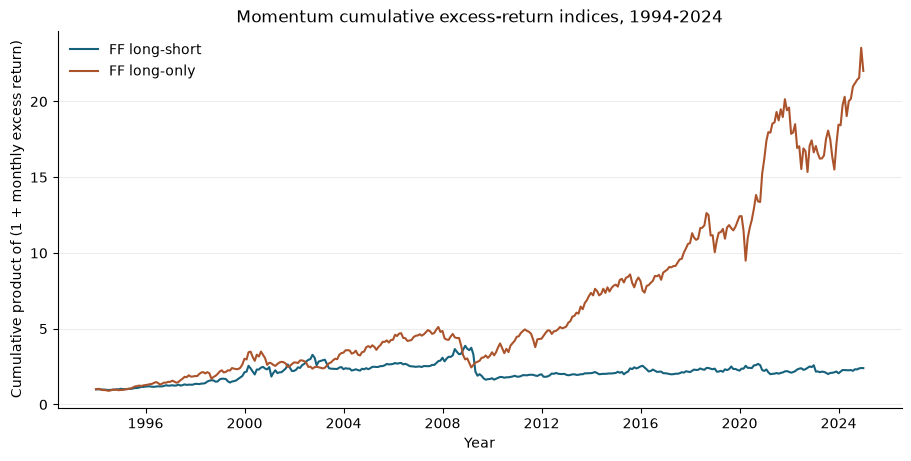

,FF long-short,FF long-only
Date,,
2024-12,2.399,22.017


In [5]:
import matplotlib.pyplot as plt

cumulative = (1 + comparison_returns).cumprod()
# Include the common initial level before the first monthly return.
plot_data = pd.concat([pd.DataFrame([[1.0, 1.0]],
                                  index=pd.PeriodIndex(['1993-12'], freq='M'),
                                  columns=cumulative.columns), cumulative])
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
for column, color in [('FF long-short', '#16627c'), ('FF long-only', '#ab542c')]:
    ax.plot(plot_data.index.to_timestamp('M'), plot_data[column], label=column, color=color)
ax.set(title='Momentum cumulative excess-return indices, 1994-2024',
       xlabel='Year', ylabel='Cumulative product of (1 + monthly excess return)')
ax.grid(axis='y', alpha=0.22)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
fig.savefig(RESULTS / 'momentum_q2_2_cumulative.png', dpi=180, bbox_inches='tight')
plt.show()
show(cumulative.iloc[[-1]])

cumulative.to_csv(RESULTS / 'momentum_q2_2_cumulative.csv')

The required product of (1 + monthly excess return) ends at 22.02 for long-only and 2.40 for long-short, starting at 1 immediately before January 1994. These are compounded excess-return indices, not literal funded wealth including the risk-free return. Both use the same 372 monthly observations.

### 2.3(a). Sensitivity to winner/loser thresholds

D1 buys decile 10 and shorts decile 1. D3 averages deciles 8-10 on the long side and 1-3 on the short side. D5 averages deciles 6-10 on the long side and 1-5 on the short side. Each has long exposure +1 and short exposure -1, without an additional RF deduction. The webpage mentions both 2023 and 2024; this analysis follows Table 3's 1994-2024 label and the adjacent comparison tables.

**Table M3. Threshold robustness, January 1994-December 2024**

In [6]:
threshold_returns = pd.DataFrame({
    'D1': deciles['Hi PRIOR'] - deciles['Lo PRIOR'],
    'D3': deciles[['PRIOR 8', 'PRIOR 9', 'Hi PRIOR']].mean(axis=1)
          - deciles[['Lo PRIOR', 'PRIOR 2', 'PRIOR 3']].mean(axis=1),
    'D5': deciles[['PRIOR 6', 'PRIOR 7', 'PRIOR 8', 'PRIOR 9', 'Hi PRIOR']].mean(axis=1)
          - deciles[['Lo PRIOR', 'PRIOR 2', 'PRIOR 3', 'PRIOR 4', 'PRIOR 5']].mean(axis=1)
}).loc['1994':'2024']
show(summary(threshold_returns, bench), percent=['Mean', 'Vol'])

summary(threshold_returns, bench).to_csv(RESULTS / 'momentum_q2_3_threshold_stats.csv')

,Mean,Vol,Sharpe,Skew,Corr MKT,Corr HML
D1,8.10%,29.96%,0.270,-1.301,-0.324,-0.237
D3,2.97%,19.37%,0.154,-1.341,-0.363,-0.212
D5,1.73%,13.43%,0.129,-1.421,-0.354,-0.209


### 2.3(b)-(d). Tradeoffs, retail implementation, and FF comparison

All three thresholds produce positive sample means and negative market/value correlations, so the qualitative effect is not confined to one cutoff. Its magnitude is sensitive: D1 has mean 8.10%, volatility 29.96%, and Sharpe 0.270, versus D5 mean 1.73%, volatility 13.43%, and Sharpe 0.129. Narrower tails strengthen the signal but concentrate risk; wider tails dilute the signal and reduce volatility. These patterns fit the lecture tradeoffs. The evidence supports robustness across thresholds, but cannot rule out data mining by itself.

For a retail product, I would retain a three-decile starting universe rather than select D1 only for its higher pre-cost Sharpe. D1 has much greater volatility and concentration. D5 broadens capacity but materially weakens the signal. Actual turnover and cost data are absent, so neither alternative has a demonstrated net-return advantage. The long-short comparisons inform signal design, not a claim that the retail fund can take these short positions.

D3 and FF UMD are directionally similar, with negative skew and negative market/value correlations. They are not identical: D3 has lower mean (2.97% versus 4.31%), higher volatility (19.37% versus 16.72%), and lower Sharpe (0.154 versus 0.257). The FF construction weights small- and large-stock spreads equally, whereas the unsegmented decile construction does not impose that size balance.

### 2.4. Does momentum require small stocks?

Small-stock momentum equals Small Winners minus Small Losers. Large-stock momentum equals Big Winners minus Big Losers. The FF factor is approximately their equal-weighted average. Reconstructing it from the rounded size-sort data differs from the supplied UMD series by at most 0.0001 in monthly return (one basis point), consistent with independent source rounding.

**Table M4. Size comparison, January 1994-December 2024**

In [7]:
small_momentum = size_sorts['SMALL HiPRIOR'] - size_sorts['SMALL LoPRIOR']
large_momentum = size_sorts['BIG HiPRIOR'] - size_sorts['BIG LoPRIOR']
reconstructed = (small_momentum + large_momentum) / 2
max_rounding_error = (reconstructed - momentum).abs().max()
assert max_rounding_error < 0.00011
size_returns = pd.DataFrame({'FF long-short': momentum,
                            'Small stocks': small_momentum,
                            'Large stocks': large_momentum}).loc['1994':'2024']
show(summary(size_returns, bench).drop(columns='Corr HML'), percent=['Mean', 'Vol'])
print(f'Maximum FF reconstruction difference from source rounding: {max_rounding_error:.4%}')

summary(size_returns, bench).drop(columns='Corr HML').to_csv(RESULTS / 'momentum_q2_4_size_stats.csv')

,Mean,Vol,Sharpe,Skew,Corr MKT
FF long-short,4.31%,16.72%,0.257,-1.461,-0.311
Small stocks,6.14%,16.91%,0.363,-1.804,-0.310
Large stocks,2.46%,18.23%,0.135,-0.874,-0.282


Maximum FF reconstruction difference from source rounding: 0.0100%


Small-stock momentum is stronger: annual mean 6.14% and Sharpe 0.363, versus 2.46% and 0.135 for large stocks. Large-stock volatility is slightly higher (18.23% versus 16.91%), so it delivers less reward at comparable risk. Both have negative market correlations. Momentum is not exclusively a small-stock phenomenon, but small stocks account for most of its average premium in this window: approximately 3.07 percentage points of the 4.31% FF mean, versus 1.23 points from large stocks. Small stocks also have more negative skew (-1.804 versus -0.874).

### 2.5. Assessment of the AQR retail product

A long-only momentum product can provide accessible exposure to recent winners and has attractive realized standalone performance in this sample. A focus on liquid larger stocks is a plausible implementation choice, because the large-stock spread remains positive. However, its pre-cost premium is much smaller than the small-stock premium, and the return data do not quantify any trading-cost savings.

The retail approach preserves the winner-selection component of the FF signal, but a long-only implementation omits the loser short leg, has strong market exposure, and may depart from FF's equal small/large weighting. Investors should therefore evaluate it as a momentum-tilted equity allocation. It should not be expected to deliver the same diversification as the academic long-short factor. The negative 2009-2024 long-short mean and substantial negative skew also argue against extrapolating the full historical premium.

I would keep a reasonably broad winner basket, use liquidity and position-size limits, and use rebalancing buffers to control unnecessary turnover. I would retain mid-cap exposure where costs permit rather than concentrate entirely in the largest stocks. Product reporting should show market exposure, momentum exposure, turnover, costs, and net performance against a suitable equity benchmark. These are implementation recommendations based on the required empirical comparisons; the supplied data cannot establish an optimal turnover policy or a post-cost Sharpe ratio.

## Sources

[Momentum Strategies assignment](https://markhendricks.github.io/finm-portfolio/case_studies/AQR%20Momentum%20Strategies.html). Data: `momentum_data.xlsx`, downloaded from the [course Box folder](https://uchicago.app.box.com/s/w3oqz9iy0kav3n3l4pa04p6etndo2ez2) on November 3, 2026. The HBS case text was not supplied; the product assessment uses the course prompt and the empirical results, without quoting proprietary exhibits.